(immune_repertoires)=

# Immune repertoires

T cells and B cells recognize antigens through their receptors. Each developing cell assembles
the genes of its receptor chains by joining a V and a J gene segment, with a D segment between
them in some chains, and nucleotides are deleted and inserted at the joints, so almost every
naive cell carries its own receptor. The junction of each chain spans the joints and encodes
the CDR3 loop that contacts the antigen; it is the most variable part of the receptor. A cell
that meets its antigen divides, and its descendants keep its receptor, so the cells of a clone
share their receptor, and an expanded clone points to an immune response.

Single-cell immune profiling sequences the receptor transcripts of each cell beside its
transcriptome. In this tutorial we import the T cell receptor (TCR) and B cell receptor (BCR)
contigs that Cell Ranger assembled for peripheral blood mononuclear cells (PBMCs), check the
chains of each cell, and group cells into clonotypes. We then locate the expanded clones in the
clusters of the expression data, compare the diversity of the clusters' repertoires and the
clonotypes they share, inspect their V and J genes and junction lengths, group B cells into
clonal families despite somatic mutations, and export the contigs for tools that build B cell
lineage trees.

## Download the PBMC example

We use "Human PBMC from a Healthy Donor, 10k cells (v2)", which 10x Genomics publishes under
CC BY 4.0. One sample of PBMCs was profiled with a 5' gene expression library, a library of 19
antibodies, and two V(D)J libraries, which enrich the TCR and BCR transcripts of the same cells;
Cell Ranger 5.0.0 processed them. We download three files, about 33 MB together: the filtered
feature-barcode matrix, with the cells that Cell Ranger called, and the filtered contig
annotations of each V(D)J library, with the contigs that it assembled with high confidence in
the barcodes it called cells.

The example uses a temporary directory. Use a project directory instead if you want to keep
the downloaded files and Zarr store after closing the notebook.

In [1]:
# Download and verify the published files.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

# Summarize the results in tables.
import pandas as pd
import cytearc

# Choose count shards that fit the import memory budget.
from cytearc.storage.count_matrix import CountMatrixPolicy

# Choose the colours of categories in plots.
from cytearc.plotting import CategoricalScale

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-10-29T05:39:59.528588Z | Wall time: 1.143 s

In [2]:
# Pin the three files so that a changed download cannot alter the example silently.
base_url = "https://cf.10xgenomics.com/samples/cell-vdj/5.0.0/sc5p_v2_hs_PBMC_10k/"
sources = {
    "expression": (
        "sc5p_v2_hs_PBMC_10k_filtered_feature_bc_matrix.h5",
        "d82e92f73fbe01bc2b41b1aa96220617cdbad53ef5387edead67daf5f012cc96",
    ),
    "tcr": (
        "sc5p_v2_hs_PBMC_10k_t_filtered_contig_annotations.csv",
        "cf6b573fc00a52b03e5aa8b25002ae9112ff7f6b355ff75a6e6a1364088223dd",
    ),
    "bcr": (
        "sc5p_v2_hs_PBMC_10k_b_filtered_contig_annotations.csv",
        "7af5eee24c16711df1707dedaf1ac0ee1fc00bd4697da29b9518d162d956d353",
    ),
}
paths = {}
for name, (file_name, expected_digest) in sources.items():
    path = output_dir / file_name

    # Name the client, because the host refuses Python's default one.
    request = Request(base_url + file_name, headers={"User-Agent": "CyteArc documentation"})

    # Copy the response in blocks without holding the file in memory.
    with urlopen(request, timeout=60) as response, path.open("wb") as target:
        shutil.copyfileobj(response, target)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(1)

expression    29.9
tcr            2.2
bcr            0.4
Name: Downloaded MB, dtype: float64

Started: 2026-10-29T05:40:00.675568Z | Wall time: 4.890 s

## Cluster the expression data

The receptors of a cell gain meaning beside its expression profile, so we start with the
expression library. Its matrix holds 36,601 genes and 19 antibody-derived tags for 10,548 cells;
`CrToZarr` writes the genes to an `RNA` assay and the tags to an `ADT` assay, with count shards
small enough for a 6 GB memory budget, as [](import_and_export.ipynb) explains. The RNA recipe
filters cells on their quality metrics, normalizes, reduces and clusters them, embeds them with
UMAP, and ranks the markers of each cluster. It takes a few minutes.

In [3]:
# Write the expression matrix into a new store.
store_path = output_dir / "pbmc_10k_v2.zarr"
cytearc.CrToZarr(
    cytearc.CrH5Reader(str(paths["expression"])),
    zarr_loc=str(store_path),
    nthreads=4,
    mem_budget="6G",
    policy=CountMatrixPolicy(unitBytes=500_000_000, chunkBytes=50_000_000),
).dump()

# Open the store and analyze its RNA assay with the standard recipe.
ds = cytearc.DataStore(str(store_path), default_assay="RNA", nthreads=4, mem_budget="6G")
run = ds.pipeline.rna(label="rna")
clusters = run["clusters"]

# Name each cluster by its strongest markers.
cluster_labels = ds.artifacts.load_values(clusters).to_pandas()
markers = ds.markers.load(marker=run["markers"])
top_markers = markers.groupby("group_id", sort=False)["feature_name"].agg(
    lambda names: ", ".join(names.head(5))
)
pd.DataFrame(
    {
        "Cells": cluster_labels.value_counts().sort_index(),
        "Top markers": top_markers.set_axis(top_markers.index.astype(cluster_labels.dtype)),
    }
).rename_axis("Cluster")

,Cells,Top markers
Cluster,,
1,2238,"ADTRP, FHIT, NOG, CHRM3-AS2, EPHX2"
2,1809,"QPCT, NLRP12, FOLR3, CES1, CLEC4E"
3,1213,"TNFRSF4, CRIP2, CD40LG, INPP4B, AQP3"
4,977,"LINC02446, CD248, CD8B, LRRN3, NELL2"
5,879,"MS4A1, FCER2, CD19, LINC00926, VPREB3"
6,733,"CLEC10A, IL1B, PID1, LGALS2, SIRPA"
7,447,"KLRF1, SH2D1B, PRSS23, FGFBP2, GNLY"
8,379,"CD8A, KLRC4, CD8B, GZMK, TIGIT"
9,281,"SLC4A10, TRDV2, RORC, TRGV9, TRAV1-2"


Started: 2026-10-29T05:40:05.568609Z | Wall time: 156.738 s

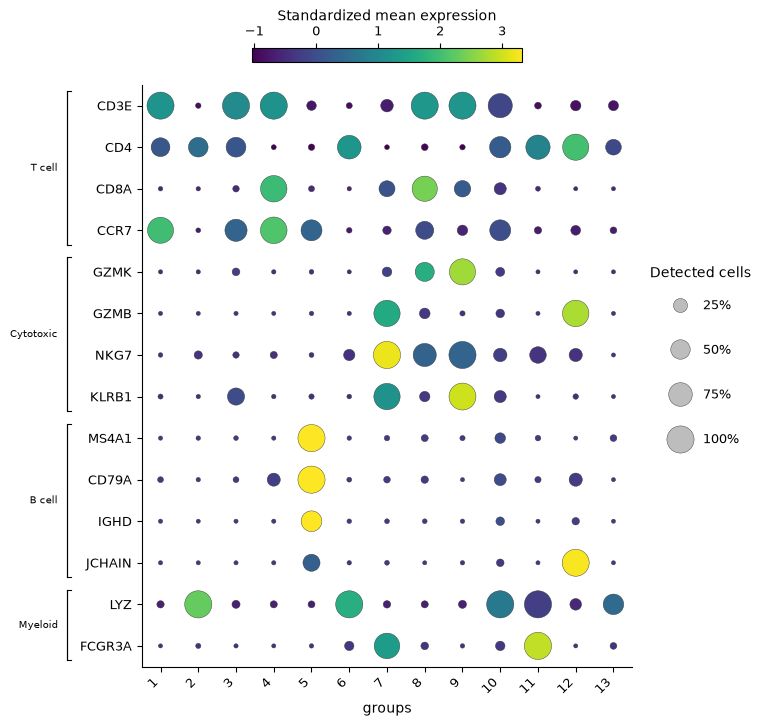

Started: 2026-10-29T05:42:42.310432Z | Wall time: 1.889 s

In [4]:
# Compare lineage markers across the clusters.
marker_panel = {
    "T cell": ["CD3E", "CD4", "CD8A", "CCR7"],
    "Cytotoxic": ["GZMK", "GZMB", "NKG7", "KLRB1"],
    "B cell": ["MS4A1", "CD79A", "IGHD", "JCHAIN"],
    "Myeloid": ["LYZ", "FCGR3A"],
}
ds.plots.dotplot(features=marker_panel, groups=clusters, standardize="feature")

The markers name most clusters. CD3E marks T cells in clusters 1, 3, 4, 8, and 9: CD4 with
CCR7 marks the naive CD4 T cells of cluster 1, and CD8A with CCR7 the naive CD8 T cells of
cluster 4. Cluster 3 holds memory CD4 T cells (CD40LG, TNFRSF4), and GZMK with CD8A marks the
effector memory CD8 T cells of cluster 8. KLRB1 with SLC4A10 and TRAV1-2 marks the
mucosal-associated invariant T (MAIT) cells of cluster 9, which also holds gamma delta T cells
(TRDV2, TRGV9). MS4A1 and CD79A mark the B cells of cluster 5. GZMB and NKG7 without CD3E mark
the NK cells of cluster 7, LYZ marks the monocytes and dendritic cells of clusters 2, 6, and 11,
cluster 12 holds plasmacytoid dendritic cells (LILRA4, JCHAIN), and cluster 13 platelets.
Cluster 10 expresses monocyte genes too; we return to it below.

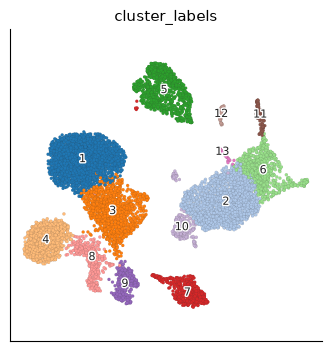

Started: 2026-10-29T05:42:44.201722Z | Wall time: 0.338 s

In [5]:
# Locate the clusters on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by=clusters)

## Import the receptor contigs

Each row of a contig annotation file is one contig: a receptor chain with its locus, its V, D,
J, and constant gene calls, its junction, and its UMI count. `repertoire.import_receptors`
joins each contig to the selected cell whose ID is its barcode. Import the TCR and BCR files
together, so that a cell with both kinds of chain is found. We import them for the cells that
the recipe analyzed, so that the receptors share the cells of its clusters and UMAP; analyzed
cells without contigs get the receptor type `no IR`. The import warns about the contigs whose
barcode matches no analyzed cell: cells that quality control removed, and barcodes that the
V(D)J analysis called cells but the expression analysis did not.

Each cell keeps up to two chains of each arm of its receptor, ranked by UMI count: the VJ arm,
of the chains that join V and J segments (TRA, IGK, and IGL), and the VDJ arm, of those that
also join a D segment (TRB and IGH). Its chains give each cell a receptor type, a subtype, and a
chain pairing, with the categories of scirpy [@Sturm_2020], which the
[repertoire API reference](/api/repertoire.html) lists.

In [6]:
# Import the TCR and BCR contigs of the analyzed cells.
receptors = ds.repertoire.import_receptors(
    [paths["tcr"], paths["bcr"]],
    cell_selection=run["analysis_cell_selection"],
)

# Count the cells of each receptor type and chain pairing.
receptor_cells = ds.repertoire.load_receptors(receptors).cells
pd.concat(
    {
        column: receptor_cells[column].value_counts(sort=False)
        for column in ("receptor_type", "chain_pairing")
    },
    names=["label", "value"],
).rename("Cells").to_frame()

Cells
label         value                 
receptor_type no IR             3406
              TCR               5049
              BCR                820
              ambiguous           78
              multichain           8
chain_pairing no IR             3406
              single pair       4612
              extra VJ           485
              orphan VJ           88
              orphan VDJ         450
              ambiguous           78
              extra VDJ          114
              two full chains    120
              multichain           8

Started: 2026-10-29T05:42:44.541992Z | Wall time: 1.044 s

Of the 9,361 analyzed cells, 5,049 carry a TCR and 820 a BCR. Most of them hold a single pair,
one chain of each arm. A second VJ chain, `extra VJ`, is common, since many T cells express
alpha chains from both alleles; `orphan VDJ` and `orphan VJ` cells lack the chain of one arm,
often lost in capture. `ambiguous` cells, with chains of both receptors, and `multichain` cells,
with more than two chains of an arm, are often doublets.

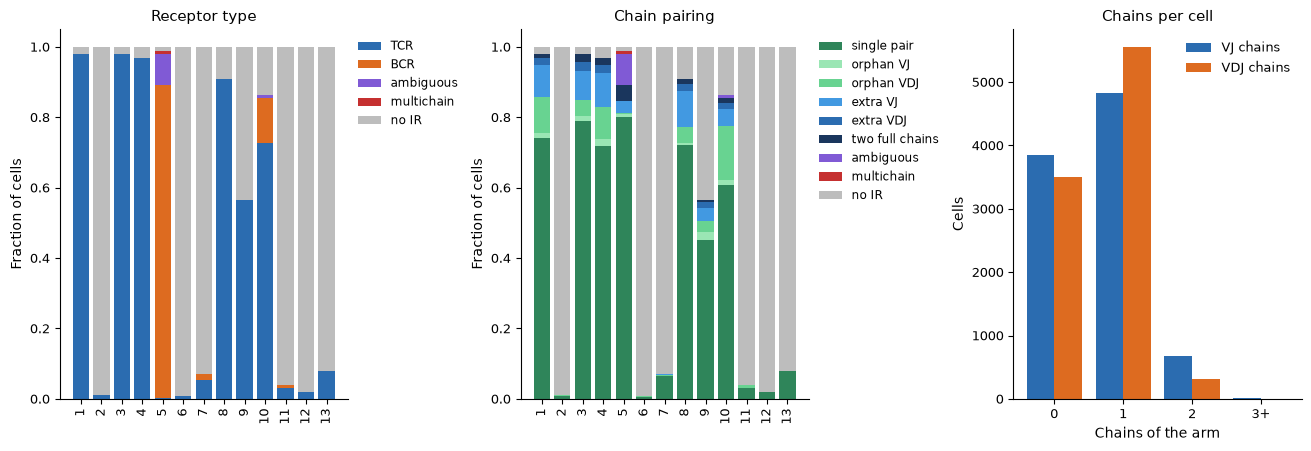

Started: 2026-10-29T05:42:45.588688Z | Wall time: 0.846 s

In [7]:
# Compare the receptors of the clusters.
ds.plots.receptor_qc(receptors, groups=clusters)

Receptors follow expression: nearly every cell of the T cell clusters carries a TCR, and nearly
every cell of cluster 5 a BCR, while monocytes and NK cells carry none. Cluster 9 is the exception
among T cells: about 40 percent of its cells have no receptor, because its gamma delta T cells
carry TRG and TRD chains, which the TCR library, made for alpha beta receptors, does not enrich.
The ambiguous and multichain cells fall in the B cell cluster. Cluster 10 expresses monocyte
genes, yet most of its cells carry a receptor.

In [8]:
# Compare each cluster's shares of cells with a TCR or a BCR and of predicted doublets.
receptor_types = receptor_cells["receptor_type"].astype(str).reindex(cluster_labels.index)
predicted_doublets = ds.artifacts.load_values(
    run["doublets"], value="predicted_doublets"
).to_pandas()
cluster_summary = pd.DataFrame(
    {
        "Cells": cluster_labels.value_counts().sort_index(),
        "TCR": (receptor_types == "TCR").groupby(cluster_labels).mean(),
        "BCR": (receptor_types == "BCR").groupby(cluster_labels).mean(),
        "Predicted doublets": predicted_doublets.reindex(cluster_labels.index)
        .groupby(cluster_labels)
        .mean(),
    }
)
cluster_summary.rename_axis("Cluster").round(2)

,Cells,TCR,BCR,Predicted doublets
Cluster,,,,
1,2238,0.98,0.00,0.00
2,1809,0.01,0.00,0.00
3,1213,0.98,0.00,0.01
4,977,0.97,0.00,0.01
5,879,0.00,0.89,0.07
6,733,0.01,0.00,0.00
7,447,0.05,0.02,0.06
8,379,0.91,0.00,0.03
9,281,0.57,0.00,0.03


Started: 2026-10-29T05:42:46.437450Z | Wall time: 0.050 s

The run's doublet detection calls 95 percent of the cells of cluster 10 doublets: droplets that
captured a monocyte together with a T or B cell, which brought its receptor. The receptors flag
other doublets themselves, as cells with chains of both receptors or more than two chains of an
arm.

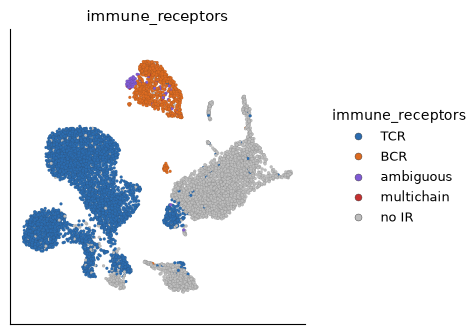

Started: 2026-10-29T05:42:46.490242Z | Wall time: 0.297 s

In [9]:
# Colour the cells of the UMAP by their receptor type, as the plot above does.
receptor_palette = {
    "TCR": "#2b6cb0",
    "BCR": "#dd6b20",
    "ambiguous": "#805ad5",
    "multichain": "#c53030",
    "no IR": "#bdbdbd",
}
receptor_colors = CategoricalScale(order=tuple(receptor_palette), palette=receptor_palette)
ds.plots.embedding(layout=run["umap"], color_by=receptors, categorical_scale=receptor_colors)

## Group cells into clonotypes

A clonotype groups the cells of one clone. By default, `repertoire.clonotypes` links two cells
whose chains have identical nucleotide junctions in both arms, or in their one arm for cells
with chains of only one, and takes the connected groups of these links as clonotypes. T cells
and B cells never share a clonotype. Options such as `sequence="aa"`, `receptor_arms`,
`dual_ir`, and `same_v_gene` change which chains must agree. Clonotypes are numbered by size, so
`clonotype_1` holds the most cells.

In [10]:
# Group the cells with a receptor into clonotypes of identical junctions.
clonotypes = ds.repertoire.clonotypes(receptors)

# List the largest clonotypes with the junctions of their primary chains.
clonotype_table = ds.repertoire.load_clonotypes(clonotypes).clonotypes
clonotype_table[
    ["n_cells", "receptor_type", "VJ_1_junction_aa", "VDJ_1_junction_aa", "VDJ_1_v_call"]
].head(10)

,n_cells,receptor_type,VJ_1_junction_aa,VDJ_1_junction_aa,VDJ_1_v_call
0,8,TCR,CICRSWGKLQF,CASSLGAPTEAFF,TRBV7-3
1,8,TCR,CAHMDSNYQLIW,CSARAVLAGDAGEQFF,TRBV20-1
2,7,TCR,CATDVSDGQKLLF,CASSIKGGLYNEQFF,TRBV19
3,4,TCR,CAGVGNTGKLIF,CASSLIGDVSYTF,TRBV7-3
4,4,TCR,CAVMDSNYQLIW,<NA>,<NA>
5,3,TCR,CATVNQGGKLIF,CSADQGYGELFF,TRBV20-1
6,3,TCR,CAMREGGDSGGGADGLTF,CASSPLGRHLGAFF,TRBV7-8
7,3,TCR,CATDAWQGAQKLVF,CASSNTPNTEAFF,TRBV4-1
8,3,TCR,CAFIPGGGADGLTF,CASSIKGGHQPQHF,TRBV19
9,3,TCR,CAAMDSNYQLIW,CASSYVEGSSYEQYF,TRBV6-5


Started: 2026-10-29T05:42:46.789792Z | Wall time: 0.284 s

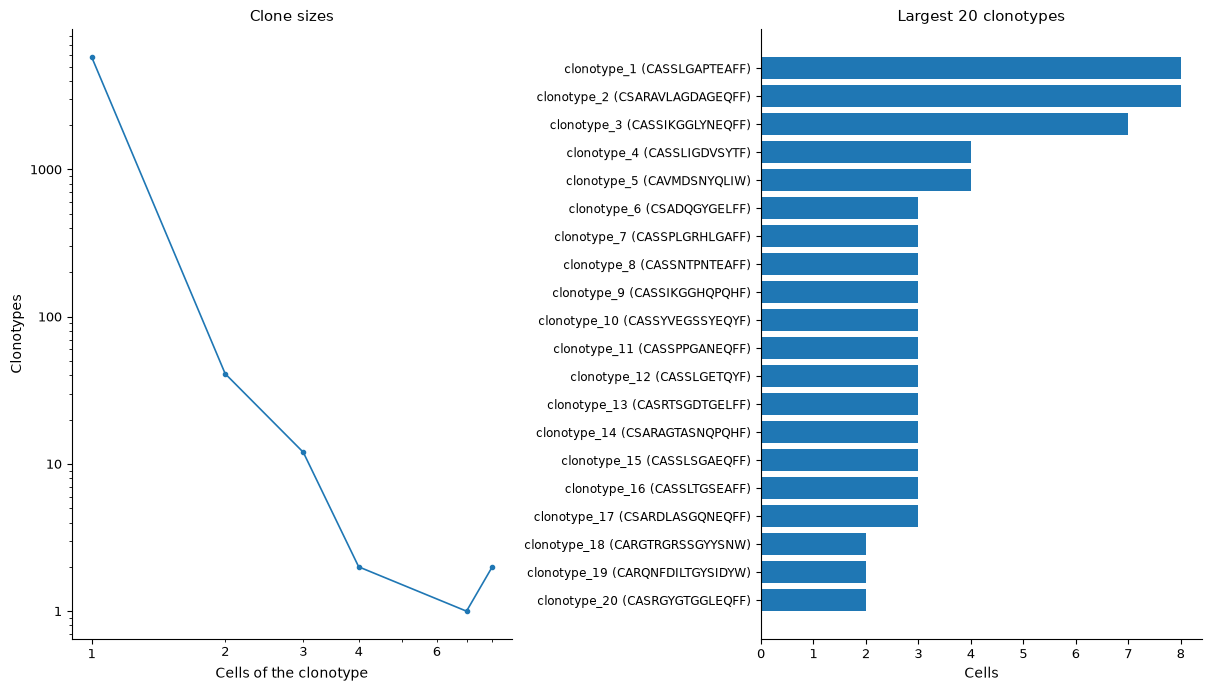

Started: 2026-10-29T05:42:47.076455Z | Wall time: 0.865 s

In [11]:
# Show how many clonotypes have each size, and the largest ones.
ds.plots.clonotype_abundance(clonotypes)

Almost every clonotype holds one cell, 5,806 of 5,864, and the largest hold 8 cells. A healthy
donor's blood holds mostly naive T and B cells, each with its own receptor, and 10,000 cells
sample a small part of a repertoire of millions of clones. `clonotype_5` holds four cells with
only an alpha chain, CAVMDSNYQLIW: the canonical alpha chain of MAIT cells, from TRAV1-2 and
TRAJ33, which many MAIT clones share. Cells with one arm are linked by that arm alone, so such a
clonotype can hold several clones; `receptor_arms` and `dual_ir` set which chains must agree.

## Find the expanded clones

`repertoire.clonal_expansion` places each cell in a category by the cells of its clonotype:
`1 cell`, `2 cells`, `3 to 5 cells`, `6 to 20 cells`, `21 to 100 cells`, and `more than 100 cells`
by default. With several samples, pass `within="sample"` so that each clonotype counts the cells
of its own sample. This example holds one sample, so every clonotype counts all its cells.

In [12]:
# Place each cell in an expansion category by the size of its clonotype.
expansion = ds.repertoire.clonal_expansion(clonotypes)

# Count the cells and clonotypes of each category, T cells and B cells apart.
expansion_record = ds.repertoire.load_clonal_expansion(expansion)
categories = expansion_record.categories
categories[categories["receptor_type"].isin(["TCR", "BCR"])].pivot(
    index="category", columns="receptor_type", values=["cells", "clonotypes"]
).reindex(list(expansion_record.labels))

cells       clonotypes      
receptor_type         BCR   TCR        BCR   TCR
category                                        
1 cell                816  4904        816  4904
2 cells                 4    78          2    39
3 to 5 cells            0    44          0    14
6 to 20 cells           0    23          0     3
21 to 100 cells         0     0          0     0
more than 100 cells     0     0          0     0

Started: 2026-10-29T05:42:47.944950Z | Wall time: 0.138 s

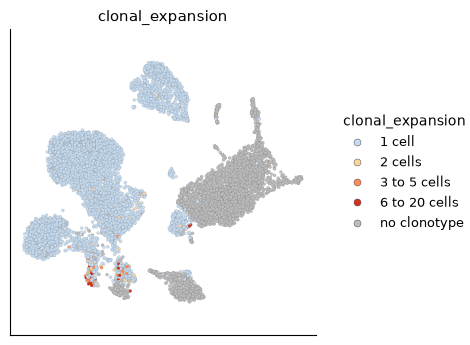

Started: 2026-10-29T05:42:48.084801Z | Wall time: 0.325 s

In [13]:
# Colour the cells of the UMAP by their expansion category, larger clones darker;
# cells without a clonotype are grey.
expansion_colors = CategoricalScale(
    palette={
        "1 cell": "#c6dbef",
        "2 cells": "#fdd49e",
        "3 to 5 cells": "#fc8d59",
        "6 to 20 cells": "#d7301f",
        "21 to 100 cells": "#990000",
        "more than 100 cells": "#4d0000",
    },
    missing_label="no clonotype",
)
ds.plots.embedding(layout=run["umap"], color_by=expansion, categorical_scale=expansion_colors)

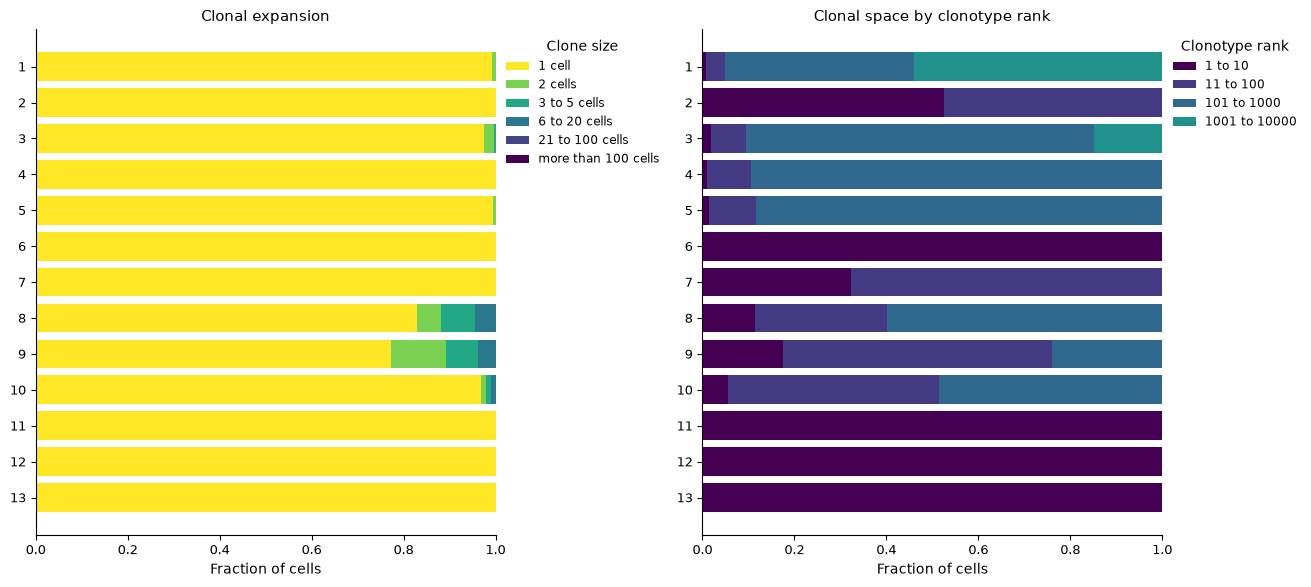

Started: 2026-10-29T05:42:48.413482Z | Wall time: 0.645 s

In [14]:
# Compare the expansion of the clusters.
ds.plots.clonal_expansion(expansion, groups=clusters)

Expanded clones gather in clusters 8 and 9, the effector memory CD8 T cells and the MAIT cells:
about a fifth of their cells belong to clonotypes of two or more cells, while the naive T cells
of clusters 1 and 4 almost never do. The right panel tells the same from the clonotypes' ranks:
the ten largest clonotypes of a naive cluster hold about one percent of its cells, and those of
clusters 8 and 9 hold 11 and 18 percent. Clusters with few cells with a receptor, such as the
monocytes, have so few clonotypes that the ten largest hold most of those cells, which says
nothing about expansion.

## Compare the diversity of the T cell clusters

From here on we compare T cell clusters. We keep the clusters in which most cells carry a TCR
and few are predicted doublets, and in them the cells with a TCR that are not predicted
doublets, so that doublets and the few T cells of other clusters do not form groups of their
own.

In [15]:
# Keep the clusters in which most cells carry a TCR and few are predicted doublets.
is_t_cluster = (cluster_summary["TCR"] > 0.5) & (cluster_summary["Predicted doublets"] < 0.5)
t_clusters = cluster_summary.index[is_t_cluster].tolist()

# Select their cells with a TCR that are not predicted doublets.
singlets = ds.select_cells(run["doublets"], value="predicted_doublets", include=[False])
t_cells = ds.select_cells(receptors, include=["TCR"], cell_selection=singlets)
t_cluster_cells = ds.select_cells(clusters, include=t_clusters, cell_selection=t_cells)
t_clusters

[1, 3, 4, 8, 9]

Started: 2026-10-29T05:42:49.060330Z | Wall time: 0.130 s

A repertoire's diversity is how many clonotypes it holds and how evenly its cells spread over
them. Every observed index depends on how many cells a group holds, because a larger sample finds
more clonotypes. Hill numbers [@Hill_1973] put the indices on one scale, the effective number of
clonotypes: order 0 counts clonotypes, order 1 weighs them by frequency, and order 2 counts the
dominant ones. `repertoire.diversity` reports them as observed, as asymptotic estimates, and at
a common size and a common sample coverage, rarefied or extrapolated as @Chao_2014 derive, so
that groups of different sizes can be compared. We compare the clusters at the common size, by
default the smallest of the groups' doubled sizes. Naive clusters, in which almost every
clonotype holds one cell, have a sample coverage near 0, so the default common coverage would
compare the clusters where each holds only a cell or two.

In [16]:
# Measure each T cell cluster's diversity.
diversity = ds.repertoire.diversity(clonotypes, groups=clusters, cell_selection=t_cluster_cells)

# Compare the Hill numbers of the clusters at their common size; the clusters'
# column is named after the artifact's kind.
hill = diversity.hill.pivot(index=clusters.kind, columns="order", values="at_size")
hill.columns = [f"Order {order} at {diversity.size} cells" for order in hill.columns]
diversity.indices.set_index(clusters.kind)[["cells", "clonotypes", "coverage"]].join(
    hill.round(1)
).rename_axis("Cluster")

,cells,clonotypes,coverage,Order 0 at 302 cells,Order 1 at 302 cells,Order 2 at 302 cells
Cluster,,,,,,
1,2187,2181,0.005489,301.9,301.8,301.8
3,1181,1168,0.021184,301.1,300.8,300.2
4,936,936,0.000002,302.0,302.0,302.0
8,336,298,0.169821,269.7,249.1,209.2
9,151,130,0.225959,238.3,210.4,154.3


Started: 2026-10-29T05:42:49.193158Z | Wall time: 0.067 s

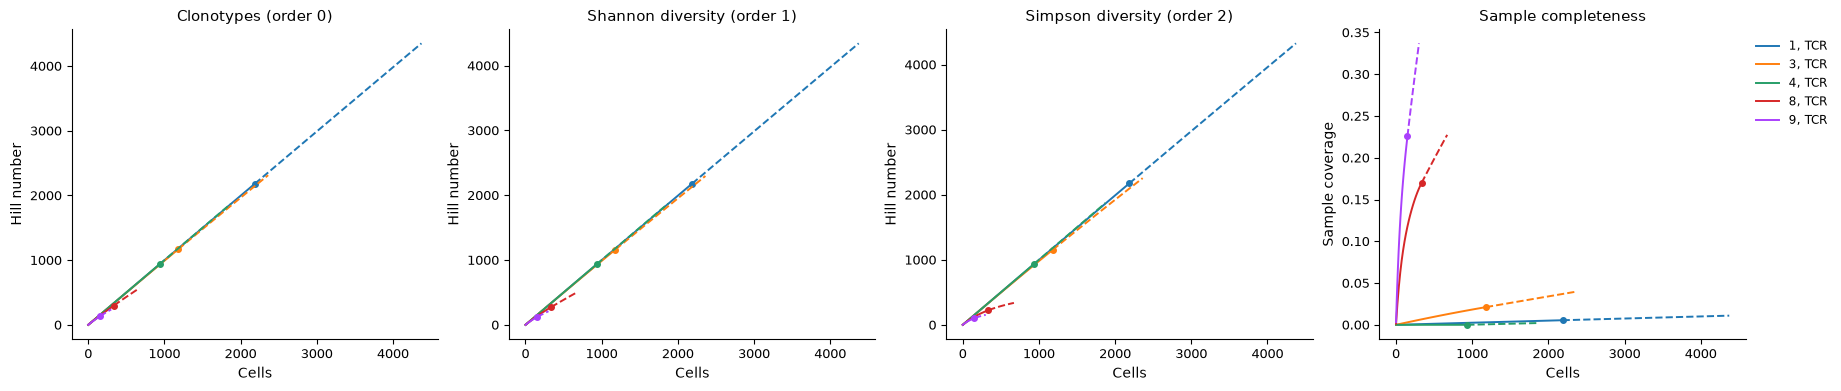

Started: 2026-10-29T05:42:49.262902Z | Wall time: 0.728 s

In [17]:
# Rarefy and extrapolate the Hill numbers of each cluster.
ds.plots.clonal_rarefaction(clonotypes, groups=clusters, cell_selection=t_cluster_cells)

At 302 cells, the naive clusters 1 and 4 hold about 302 clonotypes at every order: almost
every cell has its own, and the memory CD4 T cells of cluster 3 come close. Clusters 8 and 9 hold
fewer, and fewer still at higher orders, which weigh the large clonotypes more: 209 and 154
effective clonotypes of order 2. Cluster 9 has 151 cells, so its value at 302 cells is
extrapolated. The curves of the naive clusters rise as straight lines without approaching a
plateau, and their sample coverage stays near 0: 10,000 PBMCs sample only a small part of these
repertoires.

## Find the clonotypes that clusters share

A clone whose cells took several fates leaves its clonotype in several clusters.
`repertoire.overlap` compares every pair of groups by the clonotypes they share. The
Morisita-Horn index weighs the clonotypes by their cells: it comes near 1 when the same expanded
clones dominate both groups, and depends little on the groups' sizes. Indices that count shared
clonotypes, such as the Jaccard index, grow with the cells of both groups.

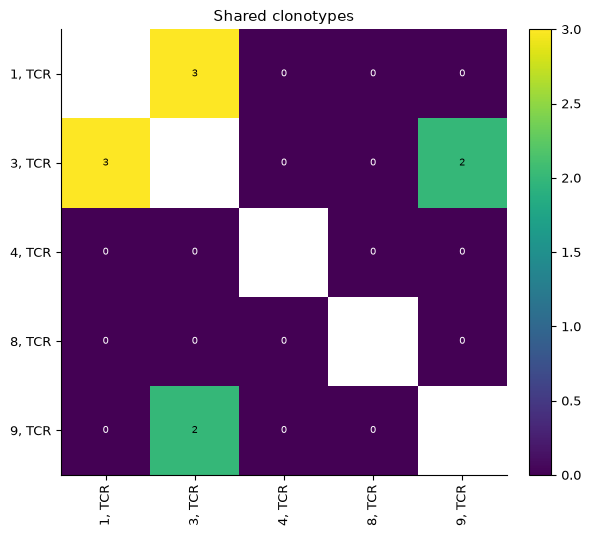

Started: 2026-10-29T05:42:49.993977Z | Wall time: 0.296 s

In [18]:
# Count the clonotypes that each pair of T cell clusters shares.
ds.plots.clonal_overlap(
    clonotypes, groups=clusters, cell_selection=t_cluster_cells, index="shared"
)

In [19]:
# List the pairs of clusters that share clonotypes, with two of the indices.
overlap = ds.repertoire.overlap(clonotypes, groups=clusters, cell_selection=t_cluster_cells)
overlap.pairs.loc[
    overlap.pairs["shared"] > 0, ["group_1", "group_2", "shared", "jaccard", "morisita_horn"]
]

,group_1,group_2,shared,jaccard,morisita_horn
0,"1, TCR","3, TCR",3,0.000897,0.001751
6,"3, TCR","9, TCR",2,0.001543,0.003160


Started: 2026-10-29T05:42:50.293087Z | Wall time: 0.068 s

The T cell clusters share almost no clonotypes: three between the naive and memory CD4 T cells,
and two between the memory CD4 T cells and cluster 9. A clone's naive and memory cells can share
a clonotype, but a naive repertoire is so diverse that a sample of it rarely meets the same clone
twice. CD4 and CD8 T cells rarely share one, since a clone commits to one lineage in the thymus.

## Compare V and J genes and junction lengths

The genes and junction lengths of a repertoire summarize how its receptors were assembled.
`repertoire.gene_usage` counts each cell's primary chain of each arm within its locus, so the
genes of TRA and TRB chains get their own shares. An expanded clone shows its genes as a peak,
and invariant T cells show their gene pairs: mucosal-associated invariant T (MAIT) cells pair
TRAV1-2 with TRAJ33, TRAJ12, or TRAJ20.

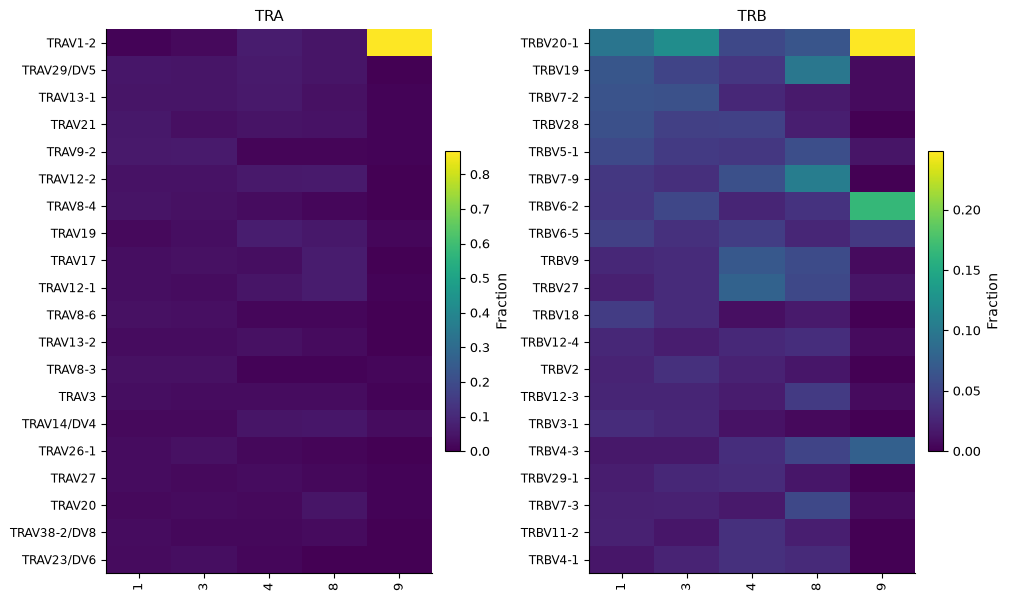

Started: 2026-10-29T05:42:50.363391Z | Wall time: 0.728 s

In [20]:
# Compare the V genes of the T cell clusters.
ds.plots.gene_usage(receptors, groups=clusters, cell_selection=t_cluster_cells, top=20)

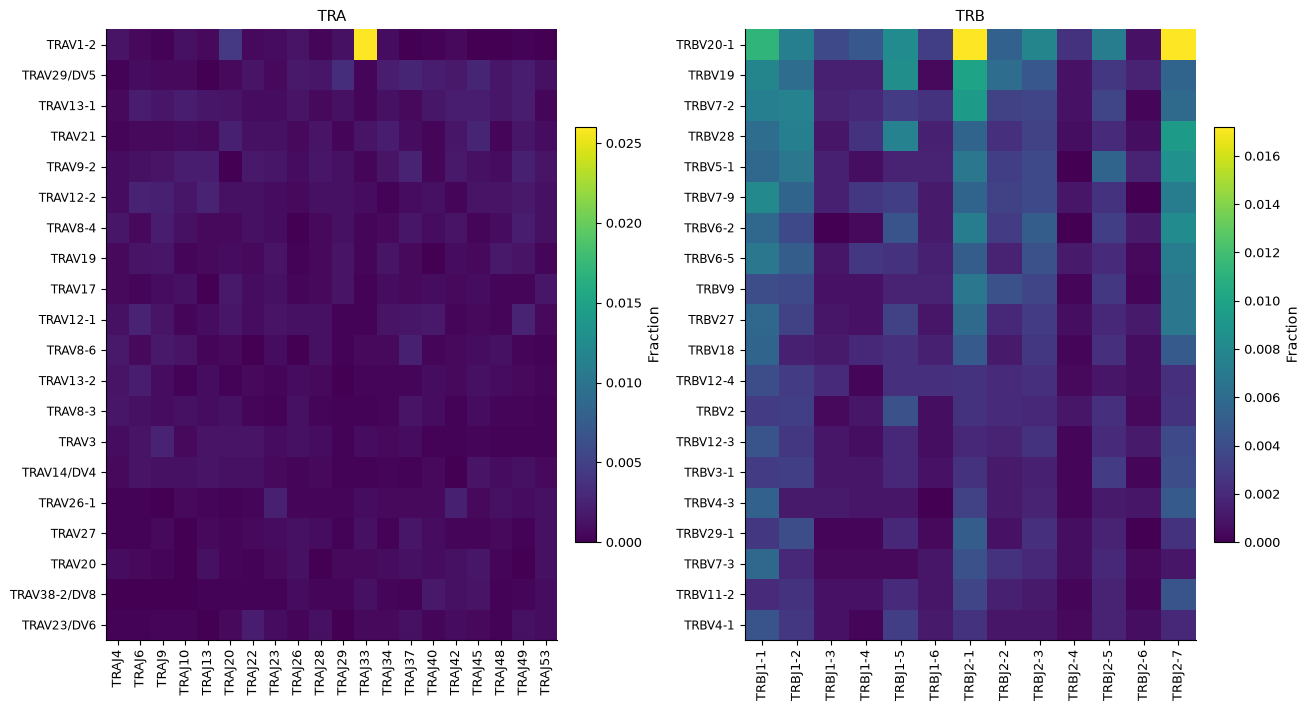

Started: 2026-10-29T05:42:51.093600Z | Wall time: 1.180 s

In [21]:
# Pair the V and J genes of each locus across the T cells.
ds.plots.gene_pairing(receptors, cell_selection=t_cluster_cells)

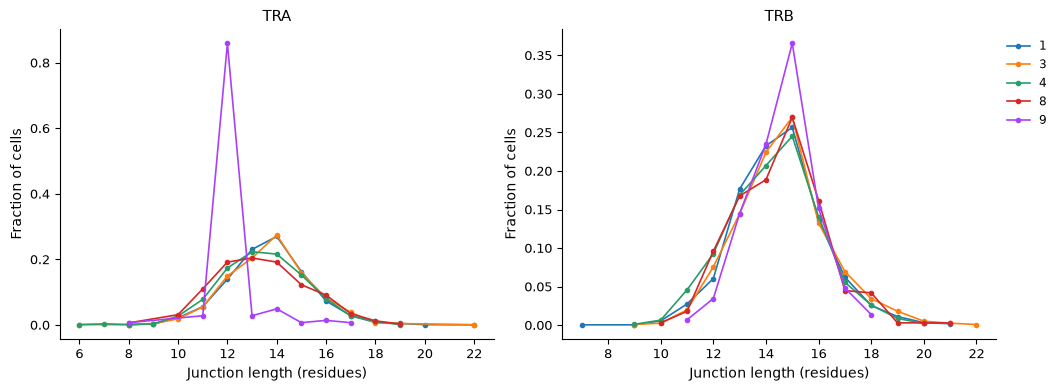

Started: 2026-10-29T05:42:52.276242Z | Wall time: 0.435 s

In [22]:
# Compare the junction lengths of the T cell clusters, in residues.
ds.plots.spectratype(receptors, groups=clusters, cell_selection=t_cluster_cells)

MAIT cells stand out: TRAV1-2 makes up more than 80 percent of the alpha chains of cluster 9,
and their beta chains favour TRBV20-1 and TRBV6 genes, as MAIT receptors do. Across the T cells,
TRAV1-2 pairs mostly with TRAJ33, and then with TRAJ20 and TRAJ12, the J genes of MAIT alpha
chains, and the alpha junctions of cluster 9 peak at 12 residues, the length of CAVMDSNYQLIW. The
other clusters spread their genes and lengths widely, as diverse repertoires do.

## Group B cells into clonal families

B cells mutate the genes of their receptor as they mature in germinal centres, so the cells of
one B cell clone can differ in their junctions. Identical junctions split such a clone apart.
`metric` links chains whose junctions are similar instead of identical: here, nucleotide
junctions of one length that differ in at most 15 percent of their positions, with the same V
and J genes. These settings follow the clonal families of B cell analyses; they decide the
families, so `cutoff` has no default. Cells that share a family under these rules descend from
one cell only as far as the rules can tell, so treat a family as a hypothesis to inspect.

In [23]:
# Link B cell chains whose nucleotide junctions differ in at most 15 percent of positions.
families = ds.repertoire.clonotypes(
    receptors,
    metric="normalized_hamming",
    cutoff=15,
    same_v_gene=True,
    same_j_gene=True,
)

# Count the B cells in clonotypes of more than one cell under each definition.
b_cell_ids = receptor_cells.index[receptor_cells["receptor_type"] == "BCR"]
pd.DataFrame(
    {
        name: {
            "Clonotypes": definition["clonotype"].nunique(),
            "B cells in clonotypes of two or more cells": int(
                (definition["clone_size"] >= 2).sum()
            ),
        }
        for name, ref in {"Identical junctions": clonotypes, "Clonal families": families}.items()
        for definition in [ds.repertoire.load_clonotypes(ref).cells.loc[b_cell_ids]]
    }
)

,Identical junctions,Clonal families
Clonotypes,818,817
B cells in clonotypes of two or more cells,4,6


Started: 2026-10-29T05:42:52.713040Z | Wall time: 1.842 s

In [24]:
# Show the B cells of the families with more than one cell, with their primary chains.
family_cells = ds.repertoire.load_clonotypes(families).cells.loc[b_cell_ids]
family_cells[family_cells["clone_size"] >= 2].join(
    receptor_cells[["VDJ_1_v_call", "VDJ_1_junction_aa", "VJ_1_v_call", "VJ_1_junction_aa"]]
).sort_values("clonotype")

,clonotype,clone_size,VDJ_1_v_call,VDJ_1_junction_aa,VJ_1_v_call,VJ_1_junction_aa
ids,,,,,,
CAACCAAGTCTTCAAG-1,clonotype_18,2,IGHV4-34,CARGTRGRSSGYYSNW,IGKV3-15,CQQYNNWPPYTF
TGCGGGTCATTGGTAC-1,clonotype_18,2,IGHV4-34,CARGTRGRSSGYYSNW,IGKV3-15,CQQYNNWPPYTF
CCACCTAAGGATGGAA-1,clonotype_19,2,IGHV4-39,CARQNFDILTGYSIDYW,IGLV1-44,CAAWDDSLNGLYVF
CCTCTGATCGTACCGG-1,clonotype_19,2,IGHV4-39,CARQNFDILTGYSIDYW,IGLV1-44,CAAWDDSLNGLYVF
ATCCACCAGATAGCAT-1,clonotype_20,2,IGHV2-5,CAHHLSFGGNWAFAHW,IGLV1-44,CAAWDDSLNGSYVF
GAGTCCGGTCTTGATG-1,clonotype_20,2,IGHV2-5,CAHHASFGGNWAFAHW,IGLV1-44,CAAWDDSLNGSYVF


Started: 2026-10-29T05:42:54.557937Z | Wall time: 0.143 s

Few B cells of blood share a clone, since most are naive: with identical junctions, only two
pairs of B cells share a clonotype. The families add one pair, `clonotype_20`: two cells with one
light chain whose heavy chain junctions differ in one residue, CAHHLSFGGNWAFAHW and
CAHHASFGGNWAFAHW, as somatic mutation leaves them.

## Export the contigs

CyteArc leaves B cell lineage trees, somatic hypermutation, and isotype switching to tools such
as Immcantation and dandelion, which compute the IMGT-gapped alignments that they need.
`repertoire.export_airr` writes the contigs as an AIRR Rearrangement file [@VanderHeiden_2018],
the format that these tools and scirpy read. Each row is one contig, with `cell_id`, the cell's
ID in this store, and, from a clonotypes artifact, `clone_id`, its cell's clonotype or family.

In [25]:
# Write the contigs with each cell's clonal family.
airr_path = output_dir / "pbmc_10k_v2_airr.tsv.gz"
ds.repertoire.export_airr(families, airr_path)

# Show the first B cell contigs of the exported file.
exported = pd.read_csv(airr_path, sep="\t", dtype=str, keep_default_na=False)
exported.loc[
    exported["locus"].isin(["IGH", "IGK", "IGL"]),
    ["sequence_id", "cell_id", "clone_id", "locus", "v_call", "j_call", "c_call", "junction_aa"],
].head()

,sequence_id,cell_id,clone_id,locus,v_call,j_call,c_call,junction_aa
15,AAACCTGTCATATCGG-1_contig_1,AAACCTGTCATATCGG-1,clonotype_347,IGK,IGKV1-8,IGKJ4,IGKC,CQQYDELPVTF
17,AAACCTGTCCGTTGTC-1_contig_1,AAACCTGTCCGTTGTC-1,clonotype_503,IGK,IGKV1-8,IGKJ1,IGKC,CQQYYSYPRTF
18,AAACCTGTCCGTTGTC-1_contig_2,AAACCTGTCCGTTGTC-1,clonotype_503,IGH,IGHV1-69D,IGHJ3,IGHM,CATTYYYDSSGYYQNDAFDIW
19,AAACCTGTCGAGAACG-1_contig_1,AAACCTGTCGAGAACG-1,clonotype_334,IGL,IGLV5-45,IGLJ3,IGLC3,CMIWHSSAWVV
20,AAACCTGTCGAGAACG-1_contig_2,AAACCTGTCGAGAACG-1,clonotype_334,IGH,IGHV1-2,IGHJ3,IGHM,CAREIEGDGVFEIW


Started: 2026-10-29T05:42:54.703652Z | Wall time: 0.829 s

Cell Ranger names contigs `<barcode>_contig_<n>` in the TCR and the BCR file alike, so a cell
with contigs in both files repeats an ID; the export gives the later ones a suffix, since the
schema requires unique IDs. The schema's required fields come first and stay empty where the
contig annotations hold no value, such as the full sequences and their alignments, which tools
such as IgBLAST compute from Cell Ranger's contig sequences.

## Next steps

This example holds one sample. With several samples or donors, pass `within="donor"` to
`repertoire.clonotypes`, so that identical receptors of two donors stay apart, and
`within="sample"` to `repertoire.clonal_expansion`. Measure diversity and overlap with
`group_by="sample"`, follow clonotypes across time points with `repertoire.track` and
`plots.clonotype_tracking`, and compare conditions with one value per sample, since the cells of
one sample are not independent observations; [](condition_comparisons.ipynb) shows such
comparisons for expression.

The [repertoire API reference](/api/repertoire.html) describes every option, the validation
against scirpy, scRepertoire, immunarch, and iNEXT, and the memory each step needs.